In [1]:
print("Hello Rocket League")

Hello Rocket League


In [45]:
import pandas as pd
with open ('rocket_league_skillshots.data','r') as file:
    lines = file.readlines();

In [46]:
print(len(lines))
print(lines[:5])


7191
['BallAcceleration Time DistanceWall DistanceCeil DistanceBall PlayerSpeed BallSpeed up accelerate slow goal left boost camera down right slide jump \n', '6 \n', '1636.7987723122642 0.0 3498.01 2012.98 299.6682700921136 104267.42623178152 99035.84933750001 0 0 0 0 0 0 0 0 1 0 1 \n', '3198.029396508704 0.13889319999999827 3494.08 2012.98 229.89677966426592 124248.03198843835 102233.87873400871 0 0 0 0 0 1 0 0 1 0 1 \n', '0.0 0.1736165000000014 3494.08 2012.98 237.35059911447462 124248.03198843835 102968.35898954592 0 0 0 0 0 1 0 0 0 0 0 \n']


In [8]:
print(lines[1].split())
print(len(lines[1].split()))

print(lines[2].split())
print(len(lines[2].split()))

['6']
1
['1636.7987723122642', '0.0', '3498.01', '2012.98', '299.6682700921136', '104267.42623178152', '99035.84933750001', '0', '0', '0', '0', '0', '0', '0', '0', '1', '0', '1']
18


In [9]:
shots = []
current_class = None
current_shot = []

for line in lines[1:]:
    values = line.split()

    if len(values) == 1:

        # Hvis vi allerede har samlet en skillshot, lagre den
        if current_class is not None and current_shot:
            shots.append((current_class, current_shot))

        current_class = int(values[0])
        current_shot = []
    else:
         # Legg målingen til nåværende skillshot
        current_shot.append(values)

if current_class is not None and current_shot:
    shots.append((current_class, current_shot))



In [10]:
print("Antall skillshots:", len(shots))

print("Klasse på første skillshot:", shots[0][0])
print("Antall målinger i første skillshot:", len(shots[0][1]))

Antall skillshots: 298
Klasse på første skillshot: 6
Antall målinger i første skillshot: 32


In [11]:
first_shot = shots[0][1]

first_shot_df = pd.DataFrame(first_shot)

first_shot_df.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,1636.7987723122642,0.0,3498.01,2012.98,299.6682700921136,104267.42623178152,99035.84933750001,0,0,0,0,0,0,0,0,1,0,1
1,3198.029396508704,0.13889319999999827,3494.08,2012.98,229.89677966426592,124248.03198843835,102233.87873400871,0,0,0,0,0,1,0,0,1,0,1
2,0.0,0.1736165000000014,3494.08,2012.98,237.35059911447462,124248.03198843835,102968.35898954592,0,0,0,0,0,1,0,0,0,0,0
3,9914.766241818943,0.3125095999999985,3500.08,2012.98,151.8809207899399,115248.01600895349,112883.12523136486,0,0,0,0,0,0,0,0,1,0,0
4,5907.747166307177,0.6250190999999994,3521.65,2013,154.55610437637202,125091.25617324338,118790.87239767204,0,0,0,0,0,0,0,0,1,0,1


In [15]:
feature_names = lines[0].split()

print(feature_names)
print(len(feature_names))

first_shot_df = pd.DataFrame(first_shot, columns=feature_names)
first_shot_df.head()

['BallAcceleration', 'Time', 'DistanceWall', 'DistanceCeil', 'DistanceBall', 'PlayerSpeed', 'BallSpeed', 'up', 'accelerate', 'slow', 'goal', 'left', 'boost', 'camera', 'down', 'right', 'slide', 'jump']
18


,BallAcceleration,Time,DistanceWall,DistanceCeil,DistanceBall,PlayerSpeed,BallSpeed,up,accelerate,slow,goal,left,boost,camera,down,right,slide,jump
0,1636.7987723122642,0.0,3498.01,2012.98,299.6682700921136,104267.42623178152,99035.84933750001,0,0,0,0,0,0,0,0,1,0,1
1,3198.029396508704,0.13889319999999827,3494.08,2012.98,229.89677966426592,124248.03198843835,102233.87873400871,0,0,0,0,0,1,0,0,1,0,1
2,0.0,0.1736165000000014,3494.08,2012.98,237.35059911447462,124248.03198843835,102968.35898954592,0,0,0,0,0,1,0,0,0,0,0
3,9914.766241818943,0.3125095999999985,3500.08,2012.98,151.8809207899399,115248.01600895349,112883.12523136486,0,0,0,0,0,0,0,0,1,0,0
4,5907.747166307177,0.6250190999999994,3521.65,2013,154.55610437637202,125091.25617324338,118790.87239767204,0,0,0,0,0,0,0,0,1,0,1


In [26]:


first_shot_df = first_shot_df.astype(float)

print(first_shot_df.dtypes)

print(first_shot_df["BallAcceleration"].mean())

print(first_shot_df["jump"].sum())


BallAcceleration    float64
Time                float64
DistanceWall        float64
DistanceCeil        float64
DistanceBall        float64
PlayerSpeed         float64
BallSpeed           float64
up                  float64
accelerate          float64
slow                float64
goal                float64
left                float64
boost               float64
camera              float64
down                float64
right               float64
slide               float64
jump                float64
dtype: object
-3853.8678846961525
9.0


In [49]:
continuous_features = {
      "BallAcceleration",
    "DistanceWall",
    "DistanceCeil",
    "DistanceBall",
    "PlayerSpeed",
    "BallSpeed"
}
input_features = [
    "up",
    "accelerate",
    "slow",
    "goal",
    "left",
    "boost",
    "camera",
    "down",
    "right",
    "slide",
    "jump"
]

class_names = [
    "Noise",
    "Ceiling Shot",
    "Power Shot",
    "Wavedash",
    "Air Dribble",
    "Front Flick",
    "Musty Flick"
]



In [50]:
processed_shots = []

for class_number, shot in shots:
    shot_df = pd.DataFrame(shot, columns=feature_names).astype(float)

    row = {}

    for feature in continuous_features:
        row[f"{feature}_mean"] = shot_df[feature].mean()
        row[f"{feature}_min"] = shot_df[feature].min()
        row[f"{feature}_max"] = shot_df[feature].max()

    for feature in input_features:
        row[f"{feature}_count"] = shot_df[feature].sum()

    row["class"] = class_number

    processed_shots.append(row)
        


In [51]:
df = pd.DataFrame(processed_shots)

df.head()

,DistanceWall_mean,DistanceWall_min,DistanceWall_max,BallAcceleration_mean,BallAcceleration_min,BallAcceleration_max,DistanceCeil_mean,DistanceCeil_min,DistanceCeil_max,BallSpeed_mean,...,slow_count,goal_count,left_count,boost_count,camera_count,down_count,right_count,slide_count,jump_count,class
0,3770.785313,3494.08,4019.92,-3853.867885,-195896.923082,33405.144871,1985.264375,1567.31,2013.16,129791.809510,...,1.0,2.0,0.0,7.0,2.0,0.0,26.0,7.0,9.0,6
1,1698.631795,28.70,3913.26,-848.813985,-57692.175539,127059.240710,1162.348462,31.19,2013.00,96963.150194,...,1.0,10.0,3.0,8.0,4.0,0.0,39.0,18.0,10.0,-1
2,1796.122941,35.49,3716.93,-1264.766385,-89020.813365,124246.293754,1158.123529,3.18,2012.99,96556.211527,...,1.0,3.0,1.0,10.0,3.0,0.0,34.0,4.0,7.0,-1
3,1072.541739,36.00,3645.31,-2133.341430,-39930.029136,8232.787624,478.427826,1.23,1151.34,121592.704957,...,0.0,0.0,0.0,7.0,3.0,0.0,23.0,8.0,11.0,-1
4,3800.485000,3481.95,3975.02,-7148.505767,-141736.497607,5120.925237,1996.488636,1932.67,2013.18,149543.364532,...,1.0,0.0,0.0,8.0,3.0,0.0,16.0,7.0,5.0,-1


In [52]:
df["class"].value_counts()

x = df.drop("class", axis=1)

y = df["class"]

print(x.shape)
print(y.shape)


(298, 29)
(298,)


In [53]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
## test_size=0.2    → 20 % test, 80 % trening
## random_state=42  → samme tilfeldige split hver gang
## stratify=y       → prøver å beholde omtrent samme fordeling
##                   av klassene i train og test

In [54]:
print(x_train.shape)
print(x_test.shape)

(238, 29)
(60, 29)


Her har jeg valgt å bruke et Decision tree som algoritme. Dette er fordi det er en classification algoritme som lager regler/splittelser basert på features som i dette datasettet er mange av. Datasettet inneholder flere forskjellige Rocket league skillshots som modellen skal klassifisere. Seiden det finnes flere enn to mulige klasser er dette et multiclass classification.

In [55]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(random_state=42)
model.fit(x_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [56]:
y_predict = model.predict(x_test)

print("Prediction:", y_predict[:10])
print("Answer:", y_test.values[:10])

Prediction: [ 6  5 -1 -1  6  3  7  1  5  6]
Answer: [ 6  5 -1 -1 -1  3 -1  1  5  7]


In [57]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_predict)

print("Accuracy:", accuracy)

Accuracy: 0.8166666666666667


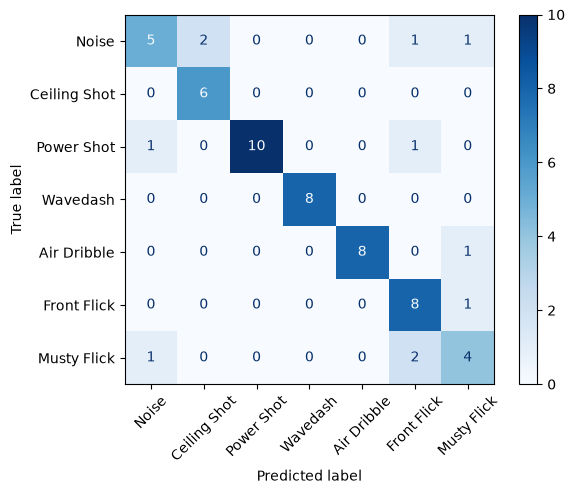

In [65]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_predict)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

# If matplotlib is not installed, run this once in a notebook cell:
# !pip install matplotlib


display.plot(cmap="Blues", values_format="d", xticks_rotation=45)
plt.show()

Modellen fikk en accuracy på 81,7 %. Confusion matrix viser at modellen klassifiserer flere av skillshot-typene godt, spesielt Ceiling Shot og Wavedash. Modellen hadde størst problemer med å klassifisere Noise og Musty Flick, og noen Musty Flicks ble blant annet klassifisert som Front Flick.
